# Model 1: 3D UNet — Kidney/Tumor Segmentation Baseline

Trains a 3D UNet on the full processed volumes to segment kidney (label 1) and tumor
(label 2), giving a Dice-based baseline directly comparable to Hatsutani et al.'s
reported numbers (tumor Dice 0.518 baseline / 0.585 with CECT-derived info / 0.615 with
their protuberance module) and Aronson et al. (kidney Dice 0.934, lesion Dice 0.711).

**Trained on CECT** -- matching your own methodology doc's pipeline diagram (Figure 1:
"Model 1: 3D UNet (segmentation), trained on CECT"), using the same
`experiment_splits/*_cases_cect.csv` files from Experiments 1-3. Nothing new to
generate.

**Honest caveat on the literature comparison:** Hatsutani et al.'s numbers come from
NCCT specifically, while this Model 1 is trained on CECT per your own pipeline design --
so this isn't a strictly apples-to-apples comparison to their figures. Worth stating
explicitly in your report rather than implying a direct comparison. If you want a truly
comparable NCCT-trained UNet later, the same code here works unchanged on
`train_cases_ncct.csv` / `val_cases_ncct.csv` instead.

**A separate notebook from your CNN classifier work** -- different data (full volumes,
not small classification patches), different architecture, different loss. Mount Drive
the same way; nothing else carries over.

**Small-dataset caution, again:** only 46 CECT training cases. A voxel-wise 3D
segmentation model has far more to overfit than the patch classifier did with the same
data -- augmentation (random flips, included below) is doing real work here, not just a
nice-to-have.

## 1. Mount Drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

DATA_DIR = "/content/drive/MyDrive/kits19_processed"


Mounted at /content/drive


## 2. Imports

In [ ]:
import os
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.optim.lr_scheduler import ReduceLROnPlateau
from torch.cuda.amp import autocast, GradScaler
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)


Device: cuda


## 3. Segmentation dataset

Unlike the classifier's patch dataset, this returns the **full** `(96,160,160)` volume
and its full 3-class mask (0=background, 1=kidney, 2=tumor) -- no patch extraction, no
label collapsing. Same fixed min-max normalization as before (HU already clipped to
`[-200, 300]` in preprocessing).

Random flips (train split only) are the augmentation your methodology doc committed to
as an overfitting safeguard for the small dataset -- applied identically to image and
mask so they stay aligned.

In [ ]:
HU_MIN, HU_MAX = -200.0, 300.0
NUM_CLASSES = 3  # background, kidney, tumor


def normalize(image):
    return (image - HU_MIN) / (HU_MAX - HU_MIN)


class KidneySegmentationDataset(Dataset):
    def __init__(self, data_dir, split_csv, augment=False, preload=True):
        self.data_dir = data_dir
        self.augment = augment
        self.preload = preload

        self.case_ids = pd.read_csv(os.path.join(data_dir, split_csv))["case_id"].tolist()

        self._cache = {}
        if preload:
            for case_id in self.case_ids:
                self._cache[case_id] = self._load_case(case_id)

    def _load_case(self, case_id):
        image = np.load(os.path.join(self.data_dir, case_id, "image.npy"))
        mask = np.load(os.path.join(self.data_dir, case_id, "mask.npy"))
        return image, mask

    def _get_case(self, case_id):
        if self.preload:
            return self._cache[case_id]
        return self._load_case(case_id)

    def __len__(self):
        return len(self.case_ids)

    def __getitem__(self, idx):
        case_id = self.case_ids[idx]
        image, mask = self._get_case(case_id)
        image = normalize(image).astype(np.float32)
        mask = mask.astype(np.int64)

        if self.augment:
            # Random flips along each spatial axis, applied identically to
            # image and mask so they stay aligned.
            for axis in (0, 1, 2):
                if np.random.rand() < 0.5:
                    image = np.flip(image, axis=axis).copy()
                    mask = np.flip(mask, axis=axis).copy()

        image_tensor = torch.from_numpy(image).unsqueeze(0)  # (1, D, H, W)
        mask_tensor = torch.from_numpy(mask)                 # (D, H, W)
        return image_tensor, mask_tensor, case_id


## 4. 3D UNet architecture

Compact 4-level UNet (3 downsampling stages + bottleneck). `96x160x160` divides cleanly
by 8 (`12x20x20` at the bottleneck), so no padding/cropping headaches at the skip
connections. GroupNorm instead of BatchNorm -- more stable at batch size 1, which is
what a T4 will likely require for full-volume 3D segmentation.

In [ ]:
def conv_block(in_ch, out_ch):
    return nn.Sequential(
        nn.Conv3d(in_ch, out_ch, 3, padding=1),
        nn.GroupNorm(min(8, out_ch), out_ch),
        nn.ReLU(inplace=True),
        nn.Conv3d(out_ch, out_ch, 3, padding=1),
        nn.GroupNorm(min(8, out_ch), out_ch),
        nn.ReLU(inplace=True),
    )


class UNet3D(nn.Module):
    def __init__(self, in_channels=1, num_classes=NUM_CLASSES, base_channels=24):
        super().__init__()
        c = base_channels

        self.enc1 = conv_block(in_channels, c)
        self.enc2 = conv_block(c, c * 2)
        self.enc3 = conv_block(c * 2, c * 4)
        self.bottleneck = conv_block(c * 4, c * 8)

        self.pool = nn.MaxPool3d(2)

        self.up3 = nn.ConvTranspose3d(c * 8, c * 4, kernel_size=2, stride=2)
        self.dec3 = conv_block(c * 8, c * 4)
        self.up2 = nn.ConvTranspose3d(c * 4, c * 2, kernel_size=2, stride=2)
        self.dec2 = conv_block(c * 4, c * 2)
        self.up1 = nn.ConvTranspose3d(c * 2, c, kernel_size=2, stride=2)
        self.dec1 = conv_block(c * 2, c)

        self.out_conv = nn.Conv3d(c, num_classes, kernel_size=1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        b = self.bottleneck(self.pool(e3))

        d3 = self.up3(b)
        d3 = self.dec3(torch.cat([d3, e3], dim=1))
        d2 = self.up2(d3)
        d2 = self.dec2(torch.cat([d2, e2], dim=1))
        d1 = self.up1(d2)
        d1 = self.dec1(torch.cat([d1, e1], dim=1))

        return self.out_conv(d1)  # (B, num_classes, D, H, W) logits


## 5. Loss and metrics

Combined weighted cross-entropy + soft Dice loss (standard nnU-Net-style choice for
this kind of extreme class imbalance -- recall from your EDA: ~99.15% background,
~0.68% kidney, ~0.17% tumor). Class weights below are a practical starting point, not
derived from exact inverse frequency (true inverse frequency would be far more extreme
and likely destabilize training) -- treat as a tunable hyperparameter if training looks
unstable.

Dice loss excludes the background class -- optimizing background Dice is trivial and
would dominate the gradient otherwise.

For reporting, `hard_dice` computes standard (non-differentiable) Dice from the model's
actual argmax predictions -- the number to quote in your report, not the soft training
loss.

In [ ]:
CLASS_WEIGHTS = torch.tensor([1.0, 5.0, 15.0])  # background, kidney, tumor


def dice_loss(logits, targets, num_classes=NUM_CLASSES, smooth=1.0):
    probs = F.softmax(logits, dim=1)
    targets_onehot = F.one_hot(targets, num_classes=num_classes).permute(0, 4, 1, 2, 3).float()

    dims = (0, 2, 3, 4)
    intersection = (probs * targets_onehot).sum(dims)
    cardinality = (probs + targets_onehot).sum(dims)
    dice_per_class = (2 * intersection + smooth) / (cardinality + smooth)

    return 1 - dice_per_class[1:].mean()  # exclude background (class 0)


def combined_loss(logits, targets, ce_weight):
    ce = F.cross_entropy(logits, targets, weight=ce_weight)
    dice = dice_loss(logits, targets)
    return ce + dice


def hard_dice(preds, targets, class_id, smooth=1e-6):
    pred_c = (preds == class_id).float()
    target_c = (targets == class_id).float()
    intersection = (pred_c * target_c).sum()
    denom = pred_c.sum() + target_c.sum()
    return ((2 * intersection + smooth) / (denom + smooth)).item()


## 6. Training loop

Batch size 1 with mixed precision (`torch.cuda.amp`) -- full `96x160x160` volumes are
too large for a bigger batch on a T4, and AMP substantially reduces the memory a 3D
UNet needs. Same overall structure as `run_epoch`/`train_baseline` from your classifier
work, for consistency, but tracking Dice instead of AUROC.

In [ ]:
def run_seg_epoch(model, loader, ce_weight, optimizer=None, scaler=None):
    is_train = optimizer is not None
    model.train() if is_train else model.eval()

    total_loss = 0.0
    n_batches = 0
    kidney_dices = []
    tumor_dices = []

    with torch.set_grad_enabled(is_train):
        for images, masks, _case_ids in loader:
            images = images.to(device)
            masks = masks.to(device)

            if is_train:
                optimizer.zero_grad()
                with autocast():
                    logits = model(images)
                    loss = combined_loss(logits, masks, ce_weight)
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
            else:
                with autocast():
                    logits = model(images)
                    loss = combined_loss(logits, masks, ce_weight)

            total_loss += loss.item()
            n_batches += 1

            preds = torch.argmax(logits, dim=1)
            kidney_dices.append(hard_dice(preds, masks, class_id=1))
            tumor_dices.append(hard_dice(preds, masks, class_id=2))

    return {
        "loss": total_loss / n_batches,
        "kidney_dice": float(np.mean(kidney_dices)),
        "tumor_dice": float(np.mean(tumor_dices)),
    }


def train_unet(name, train_csv, val_csv, num_epochs=40, lr=1e-3):
    print(f"\n===== Training {name} =====")

    train_ds = KidneySegmentationDataset(DATA_DIR, train_csv, augment=True, preload=True)
    val_ds = KidneySegmentationDataset(DATA_DIR, val_csv, augment=False, preload=True)
    train_loader = DataLoader(train_ds, batch_size=1, shuffle=True, num_workers=2, pin_memory=True)
    val_loader = DataLoader(val_ds, batch_size=1, shuffle=False, num_workers=2, pin_memory=True)

    model = UNet3D().to(device)
    ce_weight = CLASS_WEIGHTS.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    scheduler = ReduceLROnPlateau(optimizer, mode="min", patience=2, factor=0.5)
    scaler = GradScaler()

    best_val_tumor_dice = -1.0
    best_state = None
    history = []

    for epoch in range(1, num_epochs + 1):
        train_metrics = run_seg_epoch(model, train_loader, ce_weight, optimizer, scaler)
        val_metrics = run_seg_epoch(model, val_loader, ce_weight, optimizer=None)
        scheduler.step(val_metrics["loss"])

        if val_metrics["tumor_dice"] > best_val_tumor_dice:
            best_val_tumor_dice = val_metrics["tumor_dice"]
            best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}

        history.append({"epoch": epoch, **{f"train_{k}": v for k, v in train_metrics.items()},
                         **{f"val_{k}": v for k, v in val_metrics.items()}})

        current_lr = optimizer.param_groups[0]["lr"]
        print(f"[{name}] Epoch {epoch:2d} | lr {current_lr:.1e} | "
              f"train loss {train_metrics['loss']:.4f} kidney {train_metrics['kidney_dice']:.3f} tumor {train_metrics['tumor_dice']:.3f} | "
              f"val loss {val_metrics['loss']:.4f} kidney {val_metrics['kidney_dice']:.3f} tumor {val_metrics['tumor_dice']:.3f}")

    print(f"\n[{name}] Best val tumor Dice: {best_val_tumor_dice:.3f}")
    ckpt_name = f"model1_unet_{name.lower()}.pt"
    torch.save(best_state, ckpt_name)
    os.makedirs(os.path.join(DATA_DIR, "checkpoints"), exist_ok=True)
    import shutil
    shutil.copy(ckpt_name, os.path.join(DATA_DIR, "checkpoints", ckpt_name))

    return {"name": name, "best_val_tumor_dice": best_val_tumor_dice,
            "history": pd.DataFrame(history), "checkpoint": ckpt_name}


## 7. Run training

CECT training/val cases -- same files Experiments 1-3 used, no regeneration needed.

If you hit a CUDA out-of-memory error here, the fix is reducing `base_channels` in
`UNet3D()` (e.g. from 16 to 12 or 8) rather than changing the volume size -- keeping the
full volume matters more for a segmentation model than for the classifier, since Dice
loss benefits from seeing complete tumor context.

In [ ]:
cect_train_csv = "experiment_splits/train_cases_cect.csv"
cect_val_csv = "experiment_splits/val_cases_cect.csv"

unet_result = train_unet("CECT", cect_train_csv, cect_val_csv)


===== Training CECT =====


/tmp/ipykernel_3221/2899396170.py:54: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler()
/tmp/ipykernel_3221/2899396170.py:17: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():
/tmp/ipykernel_3221/2899396170.py:24: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


[CECT] Epoch  1 | lr 1.0e-03 | train loss 1.4414 kidney 0.365 tumor 0.000 | val loss 1.2322 kidney 0.340 tumor 0.000
[CECT] Epoch  2 | lr 1.0e-03 | train loss 1.1565 kidney 0.429 tumor 0.001 | val loss 1.0671 kidney 0.401 tumor 0.038
[CECT] Epoch  3 | lr 1.0e-03 | train loss 1.0199 kidney 0.557 tumor 0.020 | val loss 0.9502 kidney 0.477 tumor 0.015
[CECT] Epoch  4 | lr 1.0e-03 | train loss 0.9091 kidney 0.616 tumor 0.018 | val loss 0.8000 kidney 0.728 tumor 0.015
[CECT] Epoch  5 | lr 1.0e-03 | train loss 0.8603 kidney 0.661 tumor 0.010 | val loss 0.7580 kidney 0.755 tumor 0.002
[CECT] Epoch  6 | lr 1.0e-03 | train loss 0.7617 kidney 0.770 tumor 0.032 | val loss 0.6897 kidney 0.846 tumor 0.113
[CECT] Epoch  7 | lr 1.0e-03 | train loss 0.7236 kidney 0.786 tumor 0.085 | val loss 0.7538 kidney 0.695 tumor 0.066
[CECT] Epoch  8 | lr 1.0e-03 | train loss 0.7551 kidney 0.749 tumor 0.060 | val loss 0.6860 kidney 0.820 tumor 0.095
[CECT] Epoch  9 | lr 1.0e-03 | train loss 0.6808 kidney 0.812 tu

## 8. Training curves

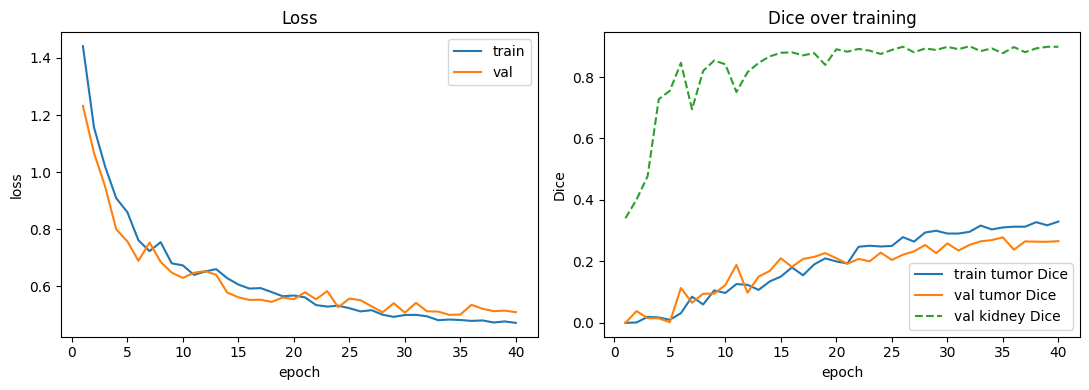

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(unet_result["history"]["epoch"], unet_result["history"]["train_loss"], label="train")
axes[0].plot(unet_result["history"]["epoch"], unet_result["history"]["val_loss"], label="val")
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("loss"); axes[0].set_title("Loss"); axes[0].legend()

axes[1].plot(unet_result["history"]["epoch"], unet_result["history"]["train_tumor_dice"], label="train tumor Dice")
axes[1].plot(unet_result["history"]["epoch"], unet_result["history"]["val_tumor_dice"], label="val tumor Dice")
axes[1].plot(unet_result["history"]["epoch"], unet_result["history"]["val_kidney_dice"], label="val kidney Dice", linestyle="--")
axes[1].set_xlabel("epoch"); axes[1].set_ylabel("Dice"); axes[1].set_title("Dice over training"); axes[1].legend()

plt.tight_layout()
plt.show()


## 9. Final test-set evaluation

Same principle as the classifier evaluations: val Dice was used to pick the "best"
checkpoint, so it's mildly optimistic. This is the once-only, honest test-set number to
report.

In [ ]:
cect_test_csv = "experiment_splits/test_cases_cect.csv"
test_ds = KidneySegmentationDataset(DATA_DIR, cect_test_csv, augment=False, preload=True)
test_loader = DataLoader(test_ds, batch_size=1, shuffle=False, num_workers=2, pin_memory=True)

model = UNet3D().to(device)
model.load_state_dict(torch.load(unet_result["checkpoint"], map_location=device))

ce_weight = CLASS_WEIGHTS.to(device)
test_metrics = run_seg_epoch(model, test_loader, ce_weight, optimizer=None)

print(f"Test kidney Dice: {test_metrics['kidney_dice']:.3f}")
print(f"Test tumor Dice:  {test_metrics['tumor_dice']:.3f}")
print(f"\nFor reference -- Hatsutani et al. (NCCT, not CECT): baseline tumor Dice 0.518, "
      f"0.585 with CECT-derived info, 0.615 with their protuberance module.")
print(f"Aronson et al. (NCCT): kidney Dice 0.934, lesion Dice 0.711.")

pd.DataFrame([{
    "model": "Model 1: 3D UNet (CECT)",
    "test_kidney_dice": test_metrics["kidney_dice"],
    "test_tumor_dice": test_metrics["tumor_dice"],
}]).to_csv(os.path.join(DATA_DIR, "results_summary_model1_unet.csv"), index=False)
print(f"\nSaved to {os.path.join(DATA_DIR, 'results_summary_model1_unet.csv')}")


/tmp/ipykernel_3221/2899396170.py:24: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


Test kidney Dice: 0.828
Test tumor Dice:  0.210

For reference -- Hatsutani et al. (NCCT, not CECT): baseline tumor Dice 0.518, 0.585 with CECT-derived info, 0.615 with their protuberance module.
Aronson et al. (NCCT): kidney Dice 0.934, lesion Dice 0.711.

Saved to /content/drive/MyDrive/kits19_processed/results_summary_model1_unet.csv
